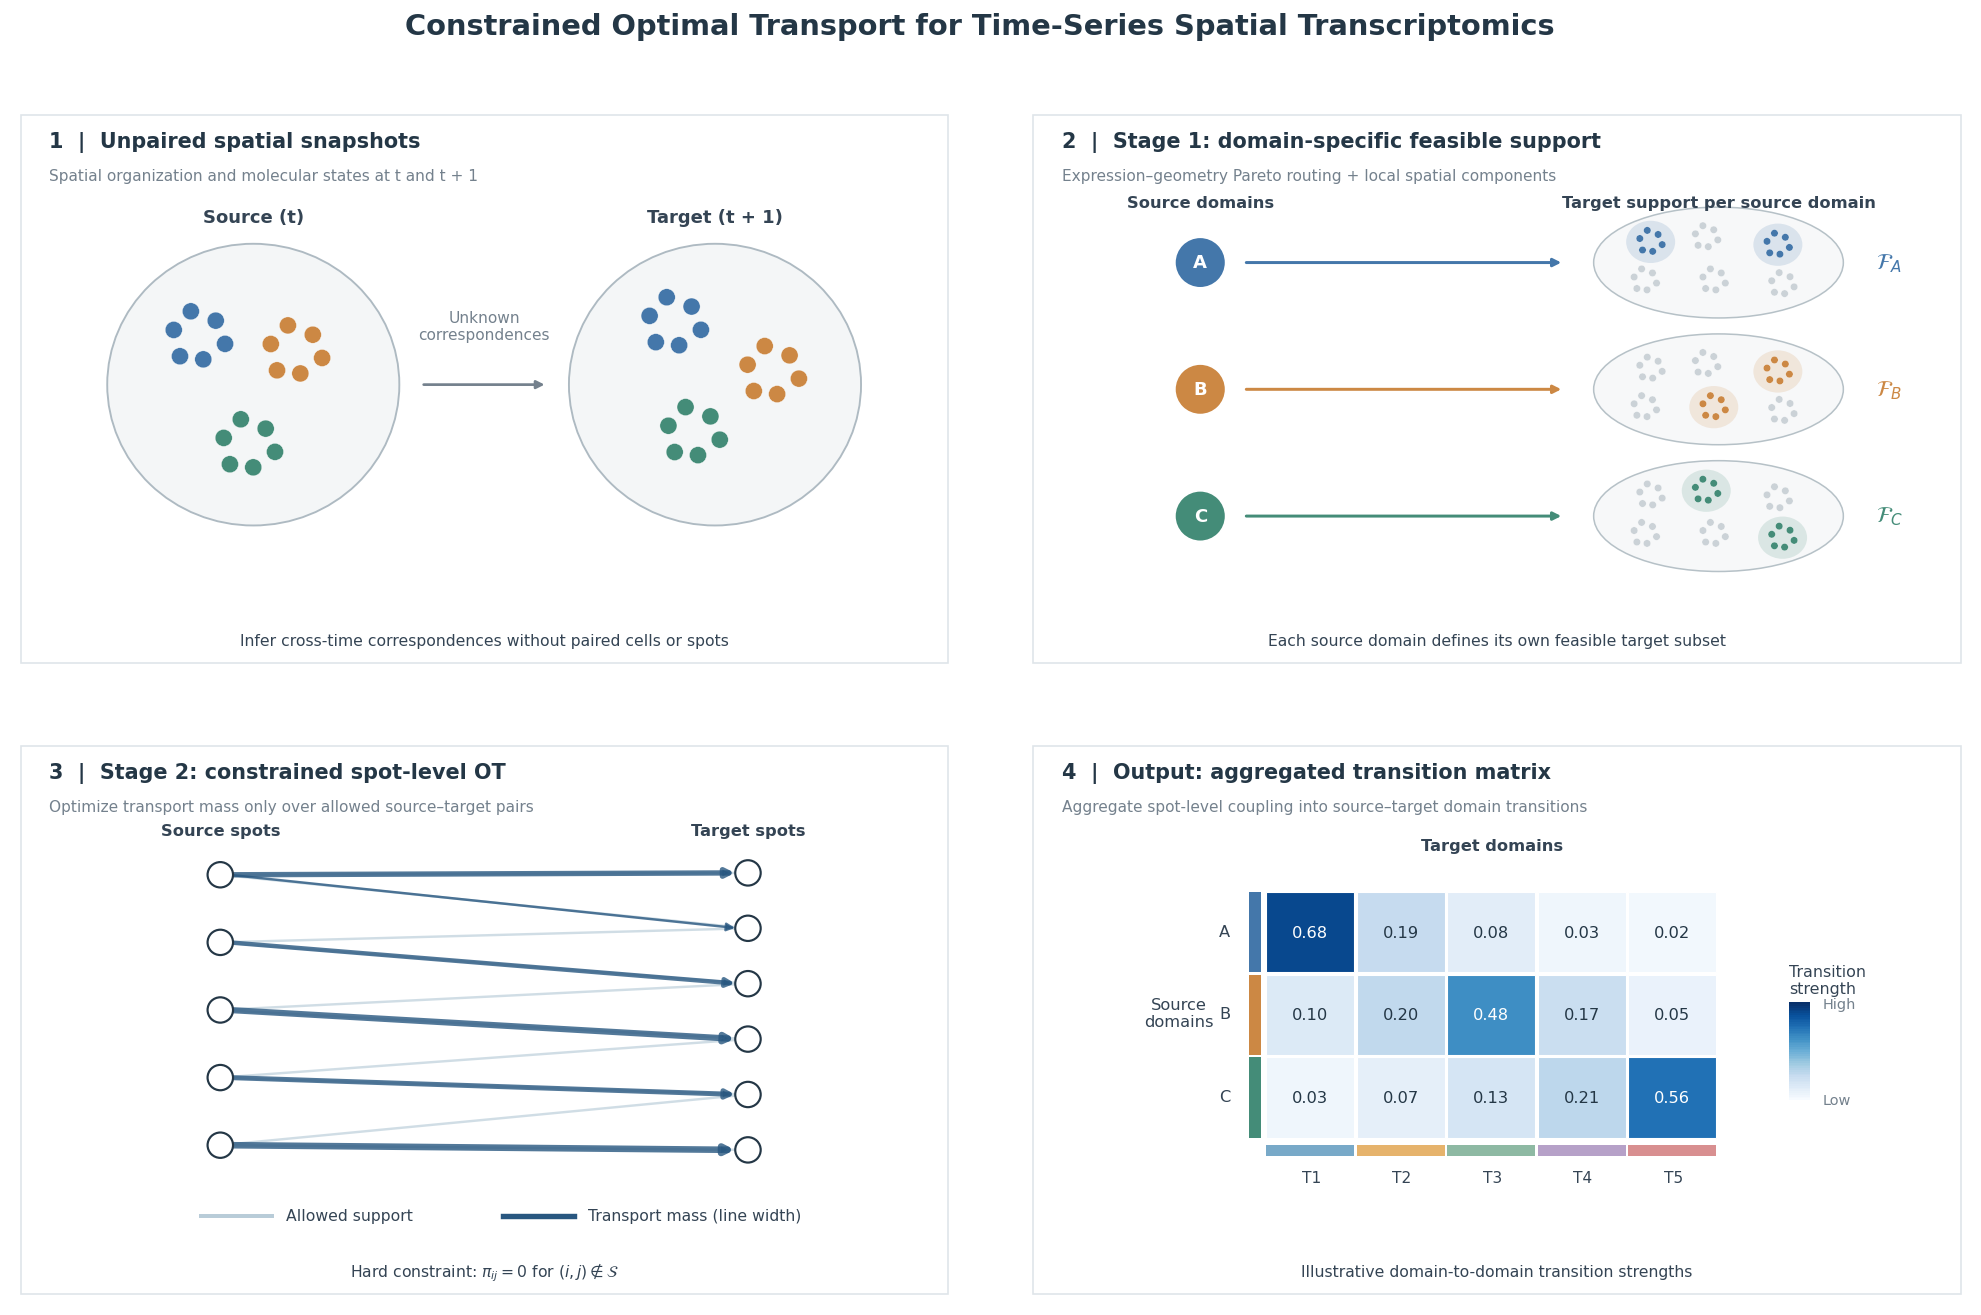

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, Rectangle, FancyArrowPatch
from matplotlib.colors import Normalize

# ============================================================
# STYLE
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
})

NAVY = "#243746"
TEXT = "#344454"
MUTED = "#74818D"
BORDER = "#DFE5E9"
LIGHT = "#F8FAFB"

# Stage 1: source-domain identity
DOMAIN_COLORS = {
    "A": "#4477AA",
    "B": "#CC8844",
    "C": "#448C78",
}

# Stage 2: transport and support
SUPPORT = "#B8CCD8"
MASS = "#285780"

TARGET_COLORS = [
    "#78A9C8", "#E6B36C", "#8EB9A3",
    "#B6A1C8", "#D88F90"
]


# ============================================================
# HELPERS
# ============================================================

def init_panel(ax, title, subtitle=None):
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 6)
    ax.set_aspect("auto")
    ax.axis("off")

    ax.add_patch(Rectangle(
        (0.08, 0.08), 9.84, 5.84,
        facecolor="white", edgecolor=BORDER,
        linewidth=0.9, zorder=-10
    ))

    ax.text(
        0.38, 5.64, title,
        fontsize=11.5, fontweight="bold",
        color=NAVY, va="center"
    )

    if subtitle:
        ax.text(
            0.38, 5.28, subtitle,
            fontsize=8.5, color=MUTED, va="center"
        )


def spot(ax, x, y, r=0.085, color="#9BA8B2",
         ec="white", lw=0.35, z=5):
    ax.add_patch(Circle(
        (x, y), r, facecolor=color,
        edgecolor=ec, linewidth=lw, zorder=z
    ))


def line_arrow(ax, start, end, color, lw=1.3,
               alpha=1.0, style="-|>", z=3):
    ax.add_patch(FancyArrowPatch(
        start, end,
        arrowstyle=style,
        mutation_scale=9,
        linewidth=lw,
        color=color,
        alpha=alpha,
        connectionstyle="arc3,rad=0",
        zorder=z
    ))


def small_spot_group(ax, cx, cy, color, scale=1):
    """Deterministic schematic spots around one domain center."""
    offsets = np.array([
        [-0.16,  0.05],
        [-0.05,  0.17],
        [ 0.11,  0.11],
        [ 0.17, -0.04],
        [ 0.03, -0.14],
        [-0.12, -0.12],
    ]) * scale

    for dx, dy in offsets:
        spot(ax, cx + dx, cy + dy,
             r=0.055 * scale,
             color=color, ec="white", lw=0.2)


def label_bottom(ax, text):
    ax.text(
        5, 0.32, text,
        ha="center", va="center",
        fontsize=8.7, color=TEXT
    )


# ============================================================
# PANEL 1: INPUT
# ============================================================

def panel1(ax):
    init_panel(
        ax,
        "1  |  Unpaired spatial snapshots",
        "Spatial organization and molecular states at t and t + 1"
    )

    centers = [(2.55, 3.05), (7.45, 3.05)]
    names = ["Source (t)", "Target (t + 1)"]

    layouts = [
        [(-0.58, 0.50), (0.45, 0.35), (-0.05, -0.65)],
        [(-0.43, 0.65), (0.61, 0.13), (-0.23, -0.52)],
    ]

    for k, ((cx, cy), name) in enumerate(zip(centers, names)):

        ax.add_patch(Ellipse(
            (cx, cy), 3.1, 3.0,
            facecolor="#F4F6F7",
            edgecolor="#AEBAC2",
            linewidth=1.05
        ))

        for i, (dx, dy) in enumerate(layouts[k]):
            small_spot_group(
                ax, cx + dx, cy + dy,
                list(DOMAIN_COLORS.values())[i],
                scale=1.65
            )

        ax.text(
            cx, 4.78, name,
            fontsize=10, fontweight="bold",
            ha="center", color=TEXT
        )

    line_arrow(
        ax, (4.32, 3.05), (5.68, 3.05),
        color=MUTED, lw=1.5
    )

    ax.text(
        5.0, 3.53,
        "Unknown\ncorrespondences",
        fontsize=8.5, ha="center",
        color=MUTED
    )

    label_bottom(
        ax,
        "Infer cross-time correspondences without paired cells or spots"
    )


# ============================================================
# PANEL 2: DOMAIN-SPECIFIC FEASIBLE SETS
# ============================================================

def draw_target_template(ax, cx, cy, selected, color):
    """
    Same target section repeated for each source domain.
    Selected local components are highlighted.
    """

    ax.add_patch(Ellipse(
        (cx, cy), 2.65, 1.18,
        facecolor="#F7F8F9",
        edgecolor="#B6C1C7",
        linewidth=0.85,
        zorder=0
    ))

    # Six schematic target spatial components
    locations = np.array([
        [-0.72,  0.22],
        [-0.13,  0.27],
        [ 0.63,  0.19],
        [-0.78, -0.19],
        [-0.05, -0.19],
        [ 0.68, -0.23]
    ])

    for i, (dx, dy) in enumerate(locations):
        x, y = cx + dx, cy + dy
        is_selected = i in selected

        if is_selected:
            ax.add_patch(Ellipse(
                (x, y), 0.52, 0.45,
                facecolor=color, edgecolor=color,
                alpha=0.16, linewidth=0, zorder=1
            ))

        small_spot_group(
            ax, x, y,
            color if is_selected else "#CBD2D7",
            scale=0.72
        )


def panel2(ax):
    init_panel(
        ax,
        "2  |  Stage 1: domain-specific feasible support",
        "Expression–geometry Pareto routing + local spatial components"
    )

    source_y = [4.35, 3.00, 1.65]

    # Illustrative supports. Not empirical results.
    feasible = {
        "A": [0, 2],
        "B": [2, 4],
        "C": [1, 5]
    }

    ax.text(
        1.85, 4.94, "Source domains",
        ha="center", fontsize=9,
        fontweight="bold", color=TEXT
    )

    ax.text(
        7.35, 4.94, "Target support per source domain",
        ha="center", fontsize=9,
        fontweight="bold", color=TEXT
    )

    for name, y in zip(["A", "B", "C"], source_y):

        color = DOMAIN_COLORS[name]

        # Source domain
        ax.add_patch(Circle(
            (1.85, y), 0.27,
            facecolor=color,
            edgecolor="white",
            linewidth=1
        ))

        ax.text(
            1.85, y, name,
            ha="center", va="center",
            fontsize=10, color="white",
            fontweight="bold"
        )

        # Routing arrow
        line_arrow(
            ax, (2.30, y), (5.72, y),
            color=color, lw=1.65
        )

        # Domain-specific target support
        draw_target_template(
            ax, cx=7.35, cy=y,
            selected=feasible[name],
            color=color
        )

        ax.text(
            9.02, y,
            rf"$\mathcal{{F}}_{{{name}}}$",
            fontsize=12, color=color,
            va="center", fontweight="bold"
        )

    label_bottom(
        ax,
        "Each source domain defines its own feasible target subset"
    )


# ============================================================
# PANEL 3: SPOT-LEVEL OT
# ============================================================

def panel3(ax):
    init_panel(
        ax,
        "3  |  Stage 2: constrained spot-level OT",
        "Optimize transport mass only over allowed source–target pairs"
    )

    src_y = np.array([4.55, 3.83, 3.11, 2.39, 1.67])
    tgt_y = np.array([4.57, 3.98, 3.39, 2.80, 2.21, 1.62])

    sx, tx = 2.2, 7.8

    ax.text(
        sx, 4.97, "Source spots",
        ha="center", fontsize=9,
        fontweight="bold", color=TEXT
    )

    ax.text(
        tx, 4.97, "Target spots",
        ha="center", fontsize=9,
        fontweight="bold", color=TEXT
    )

    # Allowed edges determined by Stage 1
    allowed_edges = [
        (0, 0), (0, 1),
        (1, 1), (1, 2),
        (2, 2), (2, 3),
        (3, 3), (3, 4),
        (4, 4), (4, 5)
    ]

    for i, j in allowed_edges:
        ax.plot(
            [sx, tx], [src_y[i], tgt_y[j]],
            color=SUPPORT,
            linewidth=1.35,
            alpha=0.65,
            zorder=1
        )

    # Selected illustrative nonzero transport masses
    masses = [
        (0, 0, 0.70),
        (0, 1, 0.18),
        (1, 2, 0.54),
        (2, 3, 0.85),
        (3, 4, 0.63),
        (4, 5, 0.92)
    ]

    for i, j, mass in masses:
        line_arrow(
            ax,
            (sx + 0.09, src_y[i]),
            (tx - 0.10, tgt_y[j]),
            color=MASS,
            lw=0.8 + 3.1 * mass,
            alpha=0.80,
            z=3
        )

    # Nodes are neutral: NOT colored by domain identity
    for y in src_y:
        spot(
            ax, sx, y, r=0.135,
            color="#FFFFFF", ec=NAVY, lw=1.2, z=6
        )

    for y in tgt_y:
        spot(
            ax, tx, y, r=0.135,
            color="#FFFFFF", ec=NAVY, lw=1.2, z=6
        )

    # Legend
    ax.plot(
        [2.0, 2.75], [0.92, 0.92],
        color=SUPPORT, lw=2.2
    )
    ax.text(
        2.9, 0.92, "Allowed support",
        va="center", fontsize=8.7, color=TEXT
    )

    ax.plot(
        [5.2, 5.95], [0.92, 0.92],
        color=MASS, lw=3.0
    )
    ax.text(
        6.1, 0.92, "Transport mass (line width)",
        va="center", fontsize=8.7, color=TEXT
    )

    label_bottom(
        ax,
        r"Hard constraint: $\pi_{ij}=0$ for $(i,j)\notin\mathcal{S}$"
    )


# ============================================================
# PANEL 4: CLUSTER-LEVEL TRANSITIONS
# ============================================================

def panel4(ax):
    init_panel(
        ax,
        "4  |  Output: aggregated transition matrix",
        "Aggregate spot-level coupling into source–target domain transitions"
    )

    # Purely illustrative values, not MOSTA measurements
    T = np.array([
        [0.68, 0.19, 0.08, 0.03, 0.02],
        [0.10, 0.20, 0.48, 0.17, 0.05],
        [0.03, 0.07, 0.13, 0.21, 0.56]
    ])

    cmap = plt.get_cmap("Blues")
    norm = Normalize(vmin=0.0, vmax=0.75)

    nrows, ncols = T.shape

    x0, y0 = 2.55, 1.75
    cw, ch = 0.96, 0.88

    # Matrix
    for i in range(nrows):
        for j in range(ncols):
            x = x0 + j * cw
            y = y0 + (nrows - 1 - i) * ch

            ax.add_patch(Rectangle(
                (x, y), cw - 0.025, ch - 0.025,
                facecolor=cmap(norm(T[i, j])),
                edgecolor="white",
                linewidth=0.6
            ))

            ax.text(
                x + (cw - 0.025) / 2,
                y + (ch - 0.025) / 2,
                f"{T[i, j]:.2f}",
                fontsize=9, ha="center", va="center",
                color="white" if T[i, j] > 0.43 else NAVY
            )

    # Source domain identity strips
    for i, name in enumerate(["A", "B", "C"]):
        y = y0 + (nrows - 1 - i) * ch

        ax.add_patch(Rectangle(
            (x0 - 0.18, y),
            0.12, ch - 0.025,
            facecolor=DOMAIN_COLORS[name],
            linewidth=0
        ))

        ax.text(
            x0 - 0.38, y + ch / 2,
            name, ha="right", va="center",
            fontsize=9, color=TEXT
        )

    # Target domain identity strips
    for j in range(ncols):
        x = x0 + j * cw

        ax.add_patch(Rectangle(
            (x, y0 - 0.19),
            cw - 0.025, 0.11,
            facecolor=TARGET_COLORS[j],
            linewidth=0
        ))

        ax.text(
            x + cw / 2, y0 - 0.34,
            f"T{j + 1}",
            ha="center", va="top",
            fontsize=8.5, color=TEXT
        )

    ax.text(
        x0 + ncols * cw / 2,
        4.81, "Target domains",
        ha="center", fontsize=9,
        fontweight="bold", color=TEXT
    )

    ax.text(
        1.62, 3.08, "Source\ndomains",
        ha="center", va="center",
        fontsize=9, color=TEXT
    )

    ax.text(
        8.1, 3.43,
        "Transition\nstrength",
        fontsize=8.8,
        color=TEXT, va="center"
    )

    # Continuous transport-mass color scale
    for k in range(55):
        val = k / 54
        ax.add_patch(Rectangle(
            (8.10, 2.15 + 1.02 * val),
            0.22, 1.02 / 54 + 0.003,
            facecolor=cmap(val),
            edgecolor="none"
        ))

    ax.text(8.45, 3.17, "High", va="center", fontsize=8, color=MUTED)
    ax.text(8.45, 2.15, "Low", va="center", fontsize=8, color=MUTED)

    label_bottom(
        ax,
        "Illustrative domain-to-domain transition strengths"
    )


# ============================================================
# DISPLAY: NO FILES SAVED
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10.5),
    dpi=130
)

panel1(axes[0, 0])
panel2(axes[0, 1])
panel3(axes[1, 0])
panel4(axes[1, 1])

fig.suptitle(
    "Constrained Optimal Transport for Time-Series Spatial Transcriptomics",
    fontsize=16,
    fontweight="bold",
    color=NAVY,
    y=0.98
)

fig.subplots_adjust(
    left=0.035,
    right=0.975,
    top=0.91,
    bottom=0.035,
    wspace=0.075,
    hspace=0.12
)

plt.show()